# Common spatial patterns

In [1]:
import matplotlib.pyplot as plt
import mne
from mne.decoding import CSP
from moabb.datasets import BNCI2014_001
import numpy as np
import os
from scipy.linalg import eigh
from scipy.signal import periodogram, hilbert
from sklearn.pipeline import Pipeline
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import StratifiedKFold, cross_val_score

np.random.seed(42)
mne.set_log_level('WARNING')


## Exercise 1: Load the data

The following uses [MOABB](https://moabb.neurotechx.com/docs/index.html) to download the [BNCI2014_001 dataset](https://moabb.neurotechx.com/docs/generated/moabb.datasets.BNCI2014_001.html) from [Tangermann et al. 2012](https://www.frontiersin.org/journals/neuroscience/articles/10.3389/fnins.2012.00055/full). The dataset contains motor imagery data with 4 classes: left hand, right hand, feet, and tongue. We will limit the data to the hands only.
1. Read the dataset documentation to get to know the data properties and the task underlying the data.

/nix/store/gy2gxav39nkcbpyw7fd0rvb4dxlj4slq-bci-BKI323-env/lib/python3.11/site-packages/moabb/datasets/download.py:97: RuntimeWarning: Setting non-standard config type: "MNE_DATASETS_BNCI_PATH"
  set_config(key, get_config("MNE_DATA"))
/nix/store/gy2gxav39nkcbpyw7fd0rvb4dxlj4slq-bci-BKI323-env/lib/python3.11/site-packages/urllib3/connectionpool.py:1063: InsecureRequestWarning: Unverified HTTPS request is being made to host 'lampx.tugraz.at'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/1.26.x/advanced-usage.html#ssl-warnings
  warnings.warn(
100%|█████████████████████████████████████| 44.1M/44.1M [00:00<00:00, 71.9GB/s]
SHA256 hash of downloaded file: 7e731ee8b681d5da6ecb11ae1d4e64b1653c7f15aad5d6b7620b25ce53141e80
Use this value as the 'known_hash' argument of 'pooch.retrieve' to ensure that the file hasn't changed if it is downloaded again in the future.
/nix/store/gy2gxav39nkcbpyw7fd0rvb4dxlj4slq-bci-BKI323-env/lib/python3.11/site-packa

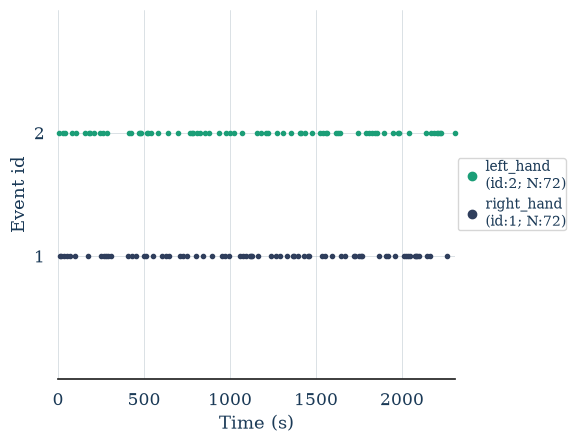

In [2]:
# Subject to analyze
i_subject = 3

# Load dataset
dataset = BNCI2014_001()
data = dataset.get_data(subjects=[i_subject])
raw = mne.concatenate_raws([r.copy() for r in data[i_subject]["1test"].values()])

# Extract events
events, event_id = mne.events_from_annotations(raw, event_id={"right_hand": 1, "left_hand": 2})

# Visualize event timeline
mne.viz.plot_events(events=events, event_id=event_id, sfreq=raw.info["sfreq"])

# Slice to epochs/trials
epo = mne.Epochs(raw, events, event_id, tmin=0.5, tmax=3.5, baseline=None, preload=True, picks="eeg", reject={"eeg":140e-6})


## Exercise 2: Fitting CSP
The most crucial prerequisite for CSP is that it is only suitable for narrowband-filtered data. But for our dataset, we do not yet know which band would be the best for the final classification performance. A first indication can be gained by visually inspecting the PSDs for the two classes separately. 

1. Look at the PSD plot. Given the PSD, which frequency bands would you have a look at?
1. Apply a bandpass filter (`mne.filter()`) to limit the frequency content to that specific band.
1. Use `epo.get_data()` to extract the data and `epo.events[:, 2] - 1` to extract the labels.
1. Fit a CSP model using MNE's `CSP()`. Set the `n_components` to 4 and the `component_order` to 'alternate'.
1. Use `mne.viz.plot_topomap()` to plot the spatial patterns stored as an attribute in your `CSP` as `patterns_`. 
1. Try out a few frequency bands and plot the resulting patterns. Which band seems to work best?

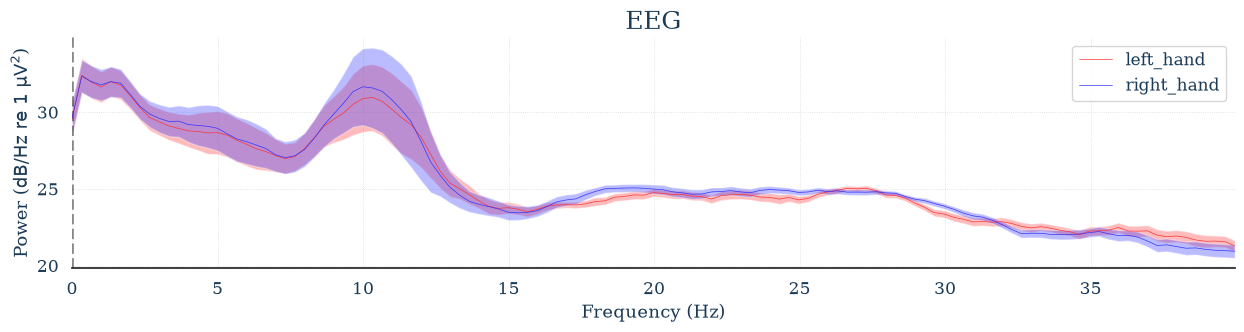

In [3]:
# Spectrum
fig, ax = plt.subplots(1, 1, figsize=(15, 3))
for i, (label, clr) in enumerate(zip(['left_hand', 'right_hand'], ['#ff3333', '#3333ff'])):
    epo[label].plot_psd(ax=ax, show=False, average=True, spatial_colors=False, color=clr, fmax=40)
    ax.get_lines()[-1].set_label(label)
ax.legend()

1. I would bandpass to 8-12Hz, right on the alpha band

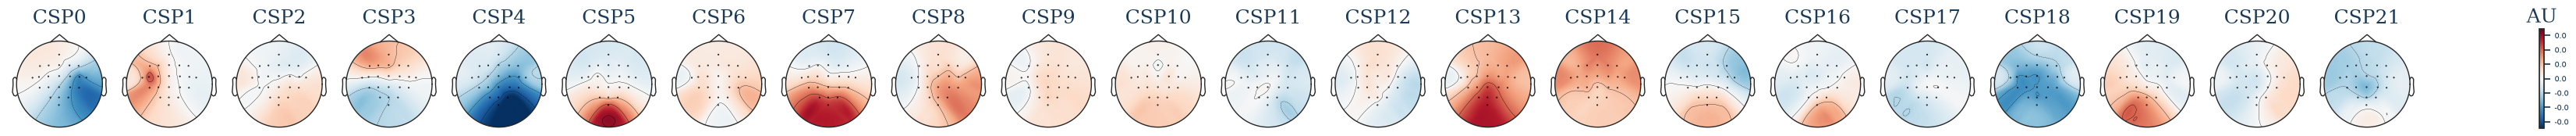

In [17]:
filtered = epo.filter(8, 12)

data = filtered.get_data()
labels = filtered.events[:, 2] - 1

csp = CSP(n_components=4, component_order="alternate")

csp.fit(data, labels)

csp.plot_patterns(filtered.info)
plt.show()  # Otherwise it shows twice
# mne.viz.plot_topomap(csp.patterns_)

## Exercise 3: Binary classification using CSP and LDA

1. Build a classifier using sklearn's `Pipeline`, a `CSP()` and an `LDA()`. In the CSP, now also set `log=True` because we use an LDA.
1. Use sklearn's `cross_val_score()` to evaluate the pipeline of the data. Print the accuracy.

In [24]:
from sklearn.model_selection import train_test_split

pipe = Pipeline([
    ("CSP", CSP(log=True)),
    ("LDA", LDA())
])

X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.33, random_state=42)

pipe.fit(X_train, y_train)

scores = cross_val_score(pipe, X_test, y_test)
print(f"{scores.mean():.2f} accuracy with a standard deviation of {scores.std():.2f}")

0.91 accuracy with a standard deviation of 0.04


## Exercise 4: Implement your own CSP

1. Build your own `fit_csp(X, y)` function that takes data `X` and labels `y` and returns the eigenvalues and eigenvectors (CSP filters) using only `numpy` functionality. Make sure that the eigenvectors are sorted on alternating eigenvalues (highest, lowest, second highest, second lowest, etc.). The CSP is computed as the generalized eigenvalue decomposition of $\Sigma_1$ and $\Sigma_2$, for which you can use scipy's `eigh()`.
1. Compare your CSP filters with those from `mne.CSP(component_order='alternate')` by visualizing its attribute `filters_` using `mne.viz.plot_topomap`.
1. The filters should be similar. What do you observe?

In [39]:


def fit_csp(X, y):
    class1, class2 = X[y], X[~y]
    
    centered1, centered2 = class1 - class1.mean(axis=1, keepdims=True), class2 - class2.mean(axis=1, keepdims=True)
    cov1, cov2 = centered1 @ centered1.T, centered2 @ centered2.T
    
    eigvals, eigvecs = eigh(cov1 + cov2)

    scale = 1 / np.sqrt(eigvals)
    whitened = (centered @ eigenvecs) * scale

    W = eigvecs / np.sqrt(np.maximum(eigvals, 1e-10))  # Avoiding div by zero

    csp_components, B = eigh(W.T @ cov1 @ W)
    eig_order = np.argsort(-np.abs(csp_components - 0.5))
    csp_components, B = csp_components[eig_order], B[:, eig_order]

    return csp_components, W @ B

csp_components, csp_vals = fit_csp(data, labels)

# csp.plot_patterns(filtered.info)
mne.viz.plot_topomap(csp_components[0], filtered.info)

ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 22 is different from 751)

## Exercise 5: Order of labels
CSP solves a generalized eigenvalue decomposition. This means that the following two objectives give the same filters, just in reversed order:
$$\arg\max_\mathbf{w}\frac{\mathbf{w}^\top\Sigma_1\mathbf{w}}{\mathbf{w}^\top\Sigma_2\mathbf{w}}, 
\arg\max_\mathbf{w}\frac{\mathbf{w}^\top\Sigma_2\mathbf{w}}{\mathbf{w}^\top\Sigma_1\mathbf{w}}
$$
1. Verify this by swapping the labels and comparing the CSP eigenvalue spectrum and filters.
2. Additionally, verify this by computing the decoding accuracy for each component and comparing with and without swapping labels.


In [7]:
# Answer here